c:\Users\Equipo\Documents\GitHub\std-jose-manuel-mestra-franco\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Equipo\Documents\GitHub\std-jose-manuel-mestra-franco\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Equipo\Documents\GitHub\std-jose-manuel-mestra-franco\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Equipo\Documents\GitHub\std-jose-manuel-mestra-franco\.venv\L

7.922306966794869

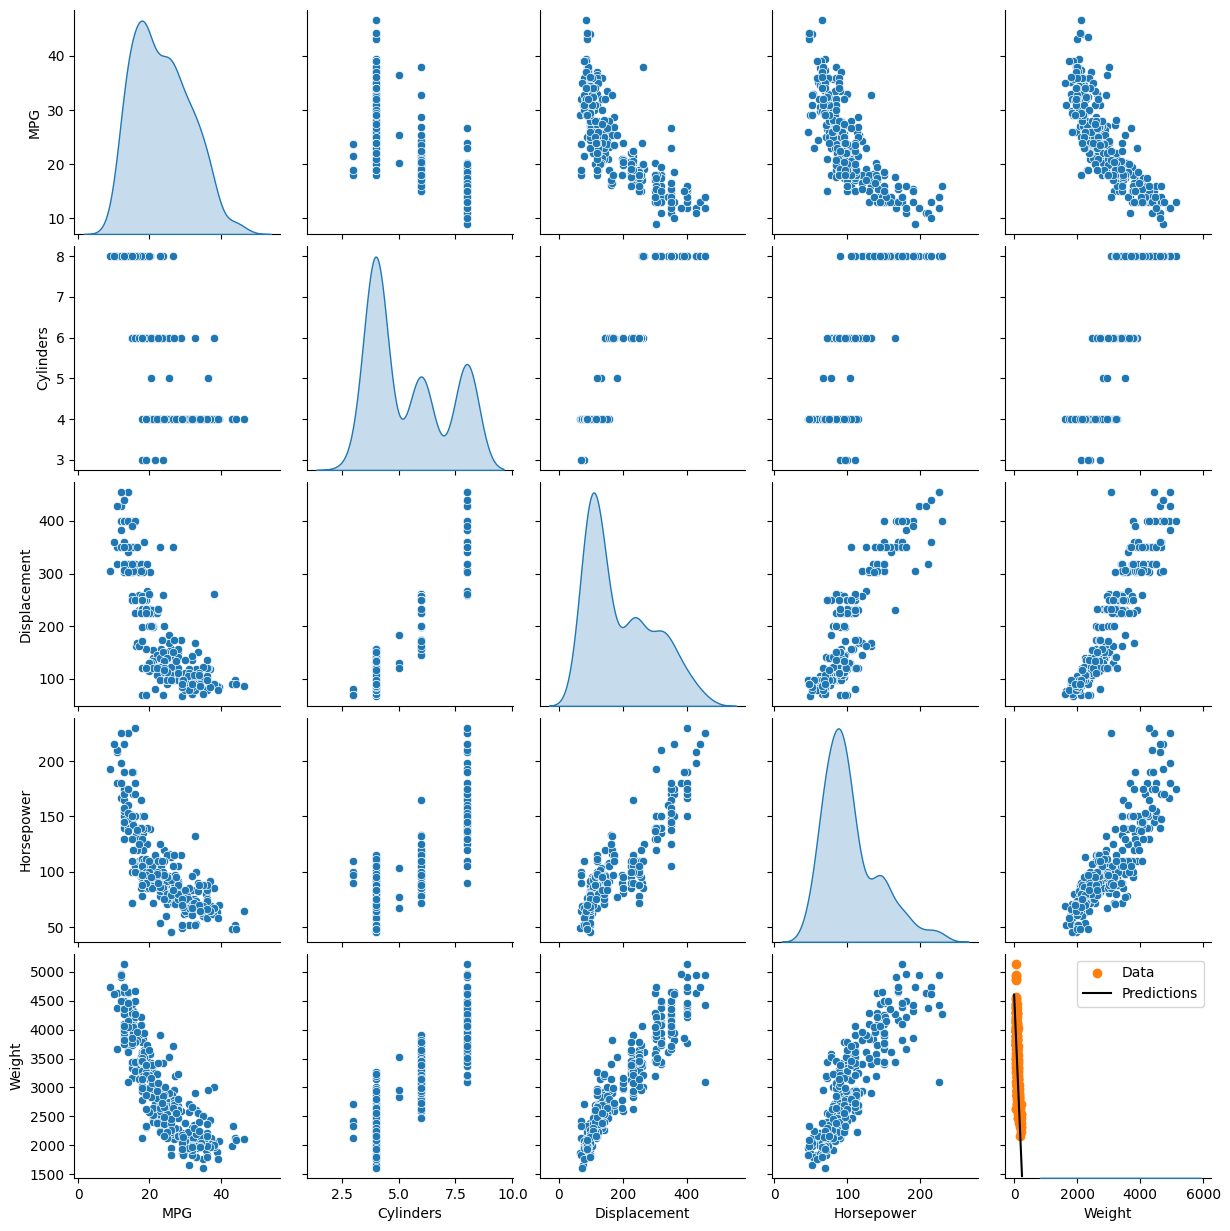

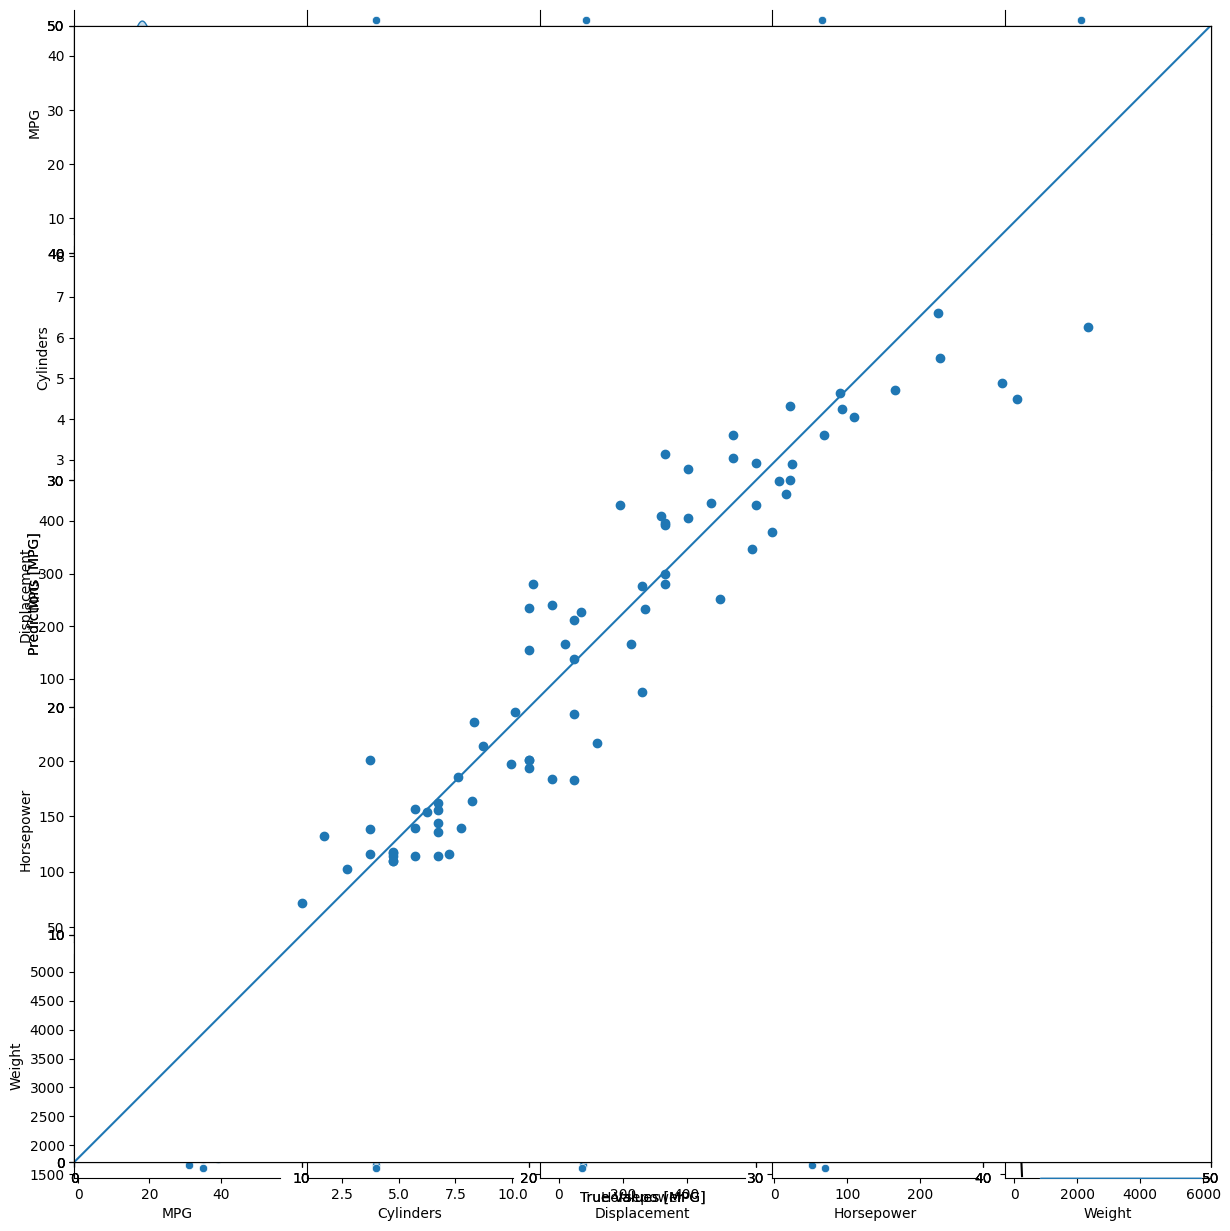

In [2]:
# ¿Cómo podemos predecir el consumo de combustible (MPG) de un automóvil a partir de sus características técnicas?

import pandas as pd

dataset = pd.read_csv("../data/auto_mpg.csv")
dataset.head()



# --

# Tamaño del dataset
dataset.shape

# --

# Búsqueda de valores nulos

dataset.isna().sum()

# --

# Remoción de valores nulos

dataset = dataset.dropna()
dataset.isna().sum()

#--

# Origin ide# ---ntifica el país de fabricación; sus valores son etiquetas, no una escala numérica.

dataset["Origin"].value_counts()

# --
 
# La categoría se conserva hasta que OneHotEncoder la transforma sin imponer un orden entre países.

dataset["Origin"] = dataset["Origin"].astype("category")
dataset.dtypes["Origin"]

# 

# Se debe conservar la categoría de origen para codificarla después de separar entrenamiento y prueba.

dataset.head()

# --

# Se deben separar vehículos para entrenamiento y prueba con una partición reproducible.

from sklearn.model_selection import train_test_split

train_dataset, test_dataset = train_test_split(
    dataset,
    train_size=0.8,
    random_state=0,
)



# ---

# Horsepower debe aparecer porque se usa directamente en la primera especificación predictiva.

import seaborn as sns

sns.pairplot(
    train_dataset[["MPG", "Cylinders", "Displacement", "Horsepower", "Weight"]],
    diag_kind="kde",
)

# ---

# Cálculo de algunas estadísticas generales

train_dataset.describe().transpose()

# ---

# Particionamiento de los datos en features y labels

train_features = train_dataset.copy()
train_labels = train_features.pop("MPG")

test_features = test_dataset.copy()
test_labels = test_features.pop("MPG")

## ---

# Se debe revisar el efecto del escalamiento solo sobre las variables numéricas.

numeric_columns = train_dataset.select_dtypes(include="number").columns

train_dataset[numeric_columns].describe().transpose()[["mean", "std"]]


# ---
# Se debe observar cómo StandardScaler centra y escala las variables numéricas.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

pd.DataFrame(
    data=scaler.fit_transform(train_dataset[numeric_columns]),
    columns=numeric_columns,
).describe().transpose()[["mean", "std"]]

# --


# Regresión lineal con una sola variable (Horsepower)

horsepower_scaler = StandardScaler()

train_horsepower = train_features[["Horsepower"]]
test_horsepower = test_features[["Horsepower"]]

horsepower_scaler.fit(train_horsepower)

standarized_train_horsepower = horsepower_scaler.transform(train_horsepower)
standarized_test_horsepower = horsepower_scaler.transform(test_horsepower)


# ---

# ---

# Modelo de regresión lineal

from sklearn.linear_model import LinearRegression

horsepower_model = LinearRegression()
horsepower_model.fit(standarized_train_horsepower, train_labels)



# ---

# Intercepto
horsepower_model.intercept_

# --



# Coeficientes
horsepower_model.coef_

# --

# Predicción. Preparación de las variables independientes

import numpy as np

x = pd.DataFrame({"Horsepower": np.linspace(0, 250, 251)})
x.head()

# --


# --

# Predicción

scaled_x = horsepower_scaler.transform(x)
y = horsepower_model.predict(scaled_x)
y[:5]


# ---


import matplotlib.pyplot as plt


def plot_horsepower(x, y):
    plt.scatter(train_features["Horsepower"], train_labels, label="Data")
    plt.plot(x, y, color="k", label="Predictions")
    plt.xlabel("Horsepower")
    plt.ylabel("MPG")
    plt.legend()

# --

plot_horsepower(x, y)


# --

# Evaluación

from sklearn.metrics import mean_squared_error

test_results = {}

y_pred = horsepower_model.predict(standarized_test_horsepower)

test_results["horsepower_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results

# -- 

# --
# Se deben ajustar el escalamiento y la codificación solo con los vehículos de entrenamiento.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = train_features.select_dtypes(include="number").columns.tolist()
categorical_features = ["Origin"]

features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "origin",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ],
)

standarized_train_features = features_preprocessor.fit_transform(train_features)
standarized_test_features = features_preprocessor.transform(test_features)

linear_model = LinearRegression()
linear_model.fit(standarized_train_features, train_labels)


# ---

# Intercepto
linear_model.intercept_

# ---

# Coeficientes
linear_model.coef_

# ---

def plot_predictions(y_true, y_pred):

    plt.axes(aspect="equal") 
    plt.scatter(y_true, y_pred)
    plt.xlabel("True Values [MPG]")
    plt.ylabel("Predictions [MPG]")
    lims = [0, 50]
    plt.xlim(lims)
    plt.ylim(lims)
    _ = plt.plot(lims, lims)


# --

test_predictions = linear_model.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


# --

test_results["linear_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)

test_results

# ---

# Se agregan un término cuadrático y una interacción Weight × Horsepower para flexibilizar el modelo lineal.

train_features_flexible = train_features.copy()
test_features_flexible = test_features.copy()

for features in [train_features_flexible, test_features_flexible]:
    features["Horsepower_squared"] = features["Horsepower"] ** 2
    features["Weight_x_Horsepower"] = features["Weight"] * features["Horsepower"]

train_features_flexible[["Horsepower", "Horsepower_squared", "Weight", "Weight_x_Horsepower"]].head()



# ---

# Se compara la regresión base con una especificación lineal que incluye los nuevos términos.

flexible_numeric_features = train_features_flexible.select_dtypes(include="number").columns.tolist()

flexible_features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), flexible_numeric_features),
        ("origin", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
)

flexible_train_features = flexible_features_preprocessor.fit_transform(train_features_flexible)
flexible_test_features = flexible_features_preprocessor.transform(test_features_flexible)

linear_flexible_model = LinearRegression()
linear_flexible_model.fit(flexible_train_features, train_labels)

flexible_predictions = linear_flexible_model.predict(flexible_test_features)
test_results["linear_flexible_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=flexible_predictions,
)

test_results


# --

# Red neuronal con una sola entrada (Horsepower)

from sklearn.neural_network import MLPRegressor

mlp_horsepower = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)
mlp_horsepower.fit(standarized_train_horsepower, train_labels)

y = mlp_horsepower.predict(scaled_x)
plot_horsepower(x, y)


# --

# --

y_pred = mlp_horsepower.predict(standarized_test_horsepower)

test_results["mlp_horsepower"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results

# --

# Red neuronal con todas las variables

mlp = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)

mlp.fit(standarized_train_features, train_labels)

test_predictions = mlp.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)




# ---
# ---

# --

# Red neuronal con todas las variables

mlp = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)

mlp.fit(standarized_train_features, train_labels)

test_predictions = mlp.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


test_results["mlp"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)


# ---

# Desempeño de los modelos

pd.DataFrame(test_results, index=["Mean squared error [MPG]"]).T.sort_values(
    by="Mean squared error [MPG]", ascending=False
)

# --

# Se almacenan los modelos, preprocesadores y la comparación de desempeño ajustados con entrenamiento.

import os
import pickle


with open("../submission/mlp.pkl", "wb") as file:
    pickle.dump(mlp, file)

with open("../submission/features_preprocessor.pkl", "wb") as file:
    pickle.dump(features_preprocessor, file)

with open("../submission/linear_flexible_model.pkl", "wb") as file:
    pickle.dump(linear_flexible_model, file)

with open("../submission/flexible_features_preprocessor.pkl", "wb") as file:
    pickle.dump(flexible_features_preprocessor, file)

pd.DataFrame(
    {
        "model": list(test_results),
        "test_mse": list(test_results.values()),
    }
).to_csv("../submission/model_comparison.csv", index=False)



# --

# La predicción reutiliza el mismo tratamiento categórico aplicado durante el ajuste.

import pandas as pd

dataset = pd.read_csv("../data/auto_mpg.csv")
dataset = dataset.dropna()
dataset["Origin"] = dataset["Origin"].astype("category")
y_true = dataset.pop("MPG")

with open("../submission/mlp.pkl", "rb") as file:
    new_mlp = pickle.load(file)

with open("../submission/features_preprocessor.pkl", "rb") as file:
    new_features_preprocessor = pickle.load(file)

standarized_dataset = new_features_preprocessor.transform(dataset)
y_pred = new_mlp.predict(standarized_dataset)

mean_squared_error(
    y_true=y_true,
    y_pred=y_pred,
)


